<a href="https://colab.research.google.com/github/RupeshReddy672/DataSciencePractice/blob/master/PracticingMethodsInDataFrames.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

### More Important Functions

In [2]:
# 1. value_counts
# 2.sort_values
# 3.rank
# 4.sort index
# 5.set index
# 6.rename index -> rename
# 7.reset index
# 8.unique & nunique
# 9.isnull/notnull/hasnans
# 10.dropna
# 11.fillna
# 12.drop_duplicates
# 13.drop
# 14.apply


# isin
# corr
# nlargest -> nsmallest
# insert
# copy

In [3]:
#1. value_counts(applicable in Series and DataFrames)

a=pd.Series([1,2,2,2,2,3,3,4,4,4,5,5])
a.value_counts(sort=False)

,count
1,1
2,4
3,2
4,3
5,2


In [4]:
marks = pd.DataFrame([
    [80,90,12],
    [90,70,11],
    [100,80,14],
    [90,70,11],
    [90,85,12],
    [110,95,18],
    [80,90,12],
    [100,95,16],
    [120,85,16]
],columns=['IQ','MARKS','PACKAGE'])

marks

,IQ,MARKS,PACKAGE
0,80,90,12
1,90,70,11
2,100,80,14
3,90,70,11
4,90,85,12
5,110,95,18
6,80,90,12
7,100,95,16
8,120,85,16


In [5]:
marks.value_counts() #frequency of the row that has same values in all the columns.


IQ   MARKS  PACKAGE
80   90     12         2
90   70     11         2
     85     12         1
100  80     14         1
     95     16         1
110  95     18         1
120  85     16         1
Name: count, dtype: int64

In [6]:
ipl = pd.read_csv('ipl-matches.csv')
ipl.head(1)

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,N,Gujarat Titans,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon


In [18]:
# find which player has won most potm -> in finals and qualifiers
ipl[~ipl['MatchNumber'].str.isdigit()]['Player_of_Match'].value_counts()

,count
Player_of_Match,
F du Plessis,3
SK Raina,3
KA Pollard,3
JJ Bumrah,2
AB de Villiers,2
MK Pandey,2
M Vijay,2
A Kumble,2
YK Pathan,2


In [8]:
ipl.sample()

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
667,548343,Chennai,2012-04-28,2012,37,Chennai Super Kings,Kings XI Punjab,"MA Chidambaram Stadium, Chepauk",Kings XI Punjab,bat,N,Kings XI Punjab,Runs,7.0,NaN,Mandeep Singh,"['F du Plessis', 'S Badrinath', 'SK Raina', 'W...","['Mandeep Singh', 'SE Marsh', 'Azhar Mahmood',...",BF Bowden,SK Tarapore


<Axes: ylabel='count'>

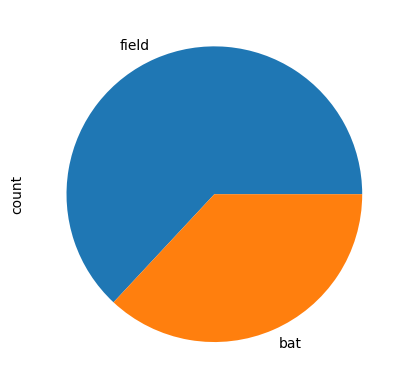

In [9]:
#Toss Decision plot
ipl['TossDecision'].value_counts().plot(kind='pie')

In [10]:
# how many matches each team has played

ipl.sample(5)

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
497,734039,Chandigarh,2014-05-25,2014,55,Kings XI Punjab,Delhi Daredevils,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,field,N,Kings XI Punjab,Wickets,7.0,NaN,M Vohra,"['V Sehwag', 'M Vohra', 'GJ Maxwell', 'DA Mill...","['KP Pietersen', 'MA Agarwal', 'KD Karthik', '...",HDPK Dharmasena,VA Kulkarni
713,501260,Dharamsala,2011-05-17,2011,63,Kings XI Punjab,Royal Challengers Bangalore,Himachal Pradesh Cricket Association Stadium,Kings XI Punjab,bat,N,Kings XI Punjab,Runs,111.0,NaN,AC Gilchrist,"['PC Valthaty', 'AC Gilchrist', 'SE Marsh', 'D...","['CH Gayle', 'SS Tiwary', 'V Kohli', 'AB de Vi...",Asad Rauf,AM Saheba
588,598036,Jaipur,2013-04-29,2013,40,Rajasthan Royals,Royal Challengers Bangalore,Sawai Mansingh Stadium,Rajasthan Royals,field,N,Rajasthan Royals,Wickets,4.0,NaN,SV Samson,"['R Dravid', 'AM Rahane', 'SV Samson', 'SR Wat...","['A Mukund', 'CH Gayle', 'V Kohli', 'AB de Vil...",M Erasmus,K Srinath
328,1082637,Chandigarh,2017-05-07,2017,47,Kings XI Punjab,Gujarat Lions,"Punjab Cricket Association IS Bindra Stadium, ...",Gujarat Lions,field,N,Gujarat Lions,Wickets,6.0,NaN,DR Smith,"['MJ Guptill', 'HM Amla', 'SE Marsh', 'GJ Maxw...","['DR Smith', 'Ishan Kishan', 'SK Raina', 'KD K...",A Nand Kishore,VK Sharma
503,734029,Ranchi,2014-05-22,2014,50,Chennai Super Kings,Sunrisers Hyderabad,JSCA International Stadium Complex,Sunrisers Hyderabad,field,N,Sunrisers Hyderabad,Wickets,6.0,NaN,DA Warner,"['DR Smith', 'F du Plessis', 'SK Raina', 'DJ H...","['DA Warner', 'S Dhawan', 'NV Ojha', 'AJ Finch...",BNJ Oxenford,C Shamshuddin


In [11]:
(ipl['Team1'].value_counts() + ipl['Team2'].value_counts() ).sort_values(ascending=False)

,count
Mumbai Indians,231
Royal Challengers Bangalore,226
Kolkata Knight Riders,223
Chennai Super Kings,208
Rajasthan Royals,192
Kings XI Punjab,190
Delhi Daredevils,161
Sunrisers Hyderabad,152
Deccan Chargers,75
Delhi Capitals,63


In [12]:
movies = pd.read_csv('movies.csv')
movies.head(4)

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,0,2019,138,Action|Drama|War,8.4,35112,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA)
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India)
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
